# asthma_GSE152004 NetCoS — disease signatures before the connectivity score

Asthmatic vs healthy-control nasal airway epithelium (GSE152004, 440 vs 254 samples). Section 0
describes the three disease-side CS inputs **before** any connectivity score, as in section 0 of
`data_exploration_ipf_CS_and_rankings.ipynb`: the DEG signature, the MITHrIL-propagated gene-level
signature and the MITHrIL pathway signature. CS distributions and drug rankings follow once the CS
runs exist.

Files (`connectivity_score/input/disease_signature_2025/asthma_GSE152004/`):
* DEG    : `asthma_GSE152004_signature_gene_id.csv` (`;`-separated, decimal comma; columns
  `gene_id, DE_log2_FC, std.error, t.value, p.value, adj.p.value`; rows = NCBI GeneID).
* MITHrIL: `asthma_GSE152004_mith3_signature.csv` (tab-separated; `gene_id, gene, Perturbation,
  p.value, adj.p.value`; nodes include genes, metabolites `chebi:` and miRNAs).
* pathways: `asthma_GSE152004_mith3_pathways.tsv` (tab-separated; `ID, Pathway Name,
  Corrected Accumulator, Adjusted pValue`).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)

DISEASE = 'asthma_GSE152004'
HERE = os.getcwd()
def _find_root(start):
    p = start
    for _ in range(6):
        if os.path.isdir(os.path.join(p, 'connectivity_score', 'input')):
            return p
        p = os.path.dirname(p)
    return None
NETCOS_ROOT = _find_root(HERE) or _find_root(os.path.dirname(HERE)) or \
    r'G:\My Drive\Professionale\Ricerca\Assegno di ricerca - Universita di Catania\netcos'

CS_IN = os.path.join(NETCOS_ROOT, 'connectivity_score', 'input', 'disease_signature_2025', DISEASE)
DEG_SIG_PATH  = os.path.join(CS_IN, f'{DISEASE}_signature_gene_id.csv')
MITH_SIG_PATH = os.path.join(CS_IN, f'{DISEASE}_mith3_signature.csv')
PW_SIG_PATH   = os.path.join(CS_IN, f'{DISEASE}_mith3_pathways.tsv')
IMG_DIR = os.path.join(NETCOS_ROOT, 'imgs', 'case_studies', DISEASE)
os.makedirs(IMG_DIR, exist_ok=True)

deg = pd.read_csv(DEG_SIG_PATH, sep=';', decimal=',', dtype={'gene_id': str})
mith = pd.read_csv(MITH_SIG_PATH, sep='\t', dtype={'gene_id': str})
deg['gene_id']  = deg['gene_id'].str.strip()
mith['gene_id'] = mith['gene_id'].str.strip()
print('DEG signature    :', deg.shape, '| cols:', list(deg.columns))
print('MITHrIL signature:', mith.shape, '| cols:', list(mith.columns))
deg.head(3)

DEG signature    : (15347, 6) | cols: ['gene_id', 'DE_log2_FC', 'std.error', 't.value', 'p.value', 'adj.p.value']
MITHrIL signature: (15825, 5) | cols: ['gene_id', 'gene', 'Perturbation', 'p.value', 'adj.p.value']


,gene_id,DE_log2_FC,std.error,t.value,p.value,adj.p.value
0,100,-0.121496,0.060202,-2.018132,0.043961,0.108539
1,10000,0.040960,0.028871,1.418702,0.156434,0.277037
2,100008588,0.181187,0.047164,3.841645,0.000133,0.001745


## 0. DEG vs MITHrIL disease signatures (before the connectivity score)

### 0.1 What is in the MITHrIL signature that is not in DEG?
Node classes by identifier: numeric Entrez id = gene, `chebi:` or `cpd:` (KEGG compound) =
metabolite, `gl:` = glycan, `dr:` = KEGG drug, anything else = miRNA (human `hsa-`, viral and
other-species miRNAs).

In [2]:
gid = mith['gene_id']
mith['node_class'] = np.select(
    [gid.str.fullmatch(r'\d+'), gid.str.startswith(('chebi', 'cpd:')), gid.str.startswith('gl:'), gid.str.startswith('dr:')],
    ['gene', 'metabolite', 'glycan', 'drug'], default='miRNA')
is_gene = mith['node_class'] == 'gene'
comp = mith['node_class'].value_counts()
comp['TOTAL'] = len(mith)
print(comp)

deg_ids  = set(deg['gene_id'])
mith_gene_ids = set(mith.loc[is_gene, 'gene_id'])
common = deg_ids & mith_gene_ids
print(f'\nDEG genes: {len(deg_ids)}   MITHrIL genes: {len(mith_gene_ids)}   common: {len(common)}')
print(f'in DEG only  : {len(deg_ids - mith_gene_ids)}')
print(f'in MITH only : {len(mith_gene_ids - deg_ids)}')

node_class
gene          11457
metabolite     2886
miRNA          1250
glycan          208
drug             24
TOTAL         15825
Name: count, dtype: int64

DEG genes: 15347   MITHrIL genes: 11457   common: 8296
in DEG only  : 7051
in MITH only : 3161


### 0.2 Do the per-gene values agree? (DEG log2FC vs MITHrIL perturbation)
Merge on `gene_id` (common genes) and correlate raw fold-change against propagated perturbation.

In [3]:
m = pd.merge(deg[['gene_id', 'DE_log2_FC', 'adj.p.value']].rename(columns={'adj.p.value': 'deg_adjp'}),
             mith.loc[is_gene, ['gene_id', 'gene', 'Perturbation', 'adj.p.value']].rename(columns={'adj.p.value': 'mith_adjp'}),
             on='gene_id', how='inner')
m = m.replace([np.inf, -np.inf], np.nan).dropna(subset=['DE_log2_FC', 'Perturbation'])
print('common genes with both values:', len(m))
pear = stats.pearsonr(m['DE_log2_FC'], m['Perturbation'])
spear = stats.spearmanr(m['DE_log2_FC'], m['Perturbation'])
sign_agree = (np.sign(m['DE_log2_FC']) == np.sign(m['Perturbation'])).mean()
print(f'Pearson  r = {pear.statistic:+.4f}  (p={pear.pvalue:.2e})')
print(f'Spearman r = {spear.statistic:+.4f}  (p={spear.pvalue:.2e})')
print(f'sign agreement = {sign_agree:.3f}  (0.5 = chance)')

common genes with both values: 8296
Pearson  r = +0.8888  (p=0.00e+00)
Spearman r = +0.9077  (p=0.00e+00)
sign agreement = 0.921  (0.5 = chance)


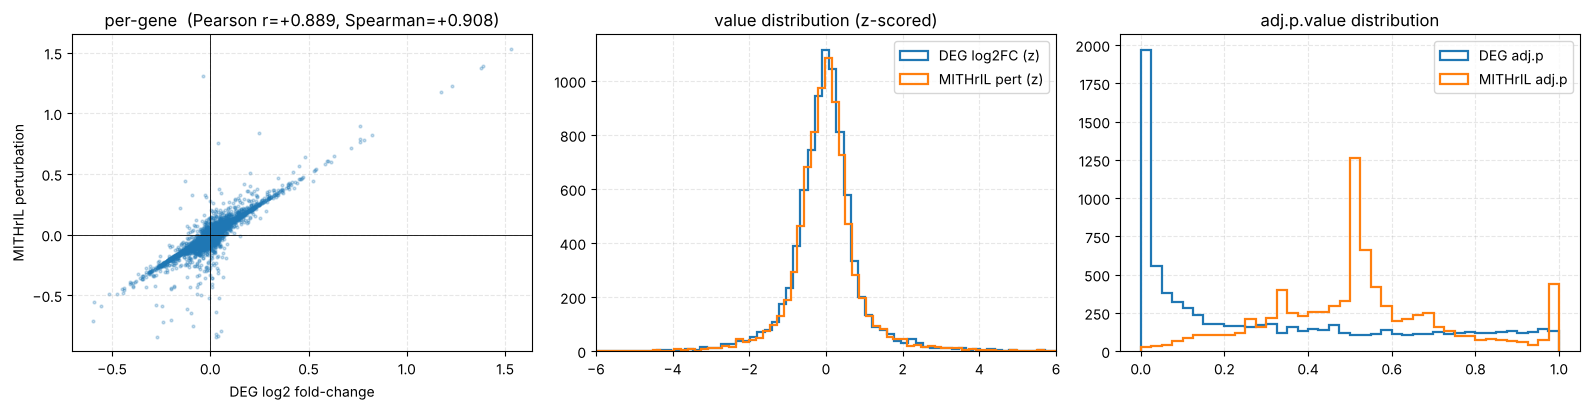

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(m['DE_log2_FC'], m['Perturbation'], s=4, alpha=0.25)
ax[0].axhline(0, color='k', lw=.6); ax[0].axvline(0, color='k', lw=.6)
ax[0].set_xlabel('DEG log2 fold-change'); ax[0].set_ylabel('MITHrIL perturbation')
ax[0].set_title(f'per-gene  (Pearson r={pear.statistic:+.3f}, Spearman={spear.statistic:+.3f})')
ax[0].grid(ls='--', alpha=.3)
ax[1].hist((m['DE_log2_FC']-m['DE_log2_FC'].mean())/m['DE_log2_FC'].std(), bins=120,
           histtype='step', lw=1.6, label='DEG log2FC (z)')
ax[1].hist((m['Perturbation']-m['Perturbation'].mean())/m['Perturbation'].std(), bins=120,
           histtype='step', lw=1.6, label='MITHrIL pert (z)')
ax[1].set_title('value distribution (z-scored)'); ax[1].legend(); ax[1].grid(ls='--', alpha=.3)
ax[1].set_xlim(-6, 6)
ax[2].hist(m['deg_adjp'], bins=40, histtype='step', lw=1.6, label='DEG adj.p')
ax[2].hist(m['mith_adjp'], bins=40, histtype='step', lw=1.6, label='MITHrIL adj.p')
ax[2].set_title('adj.p.value distribution'); ax[2].legend(); ax[2].grid(ls='--', alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_deg_vs_mith_signature.png'), dpi=120)
plt.show()

### 0.3 Significance agreement
How often is a gene significant (adj.p ≤ 0.05) in DEG vs after MITHrIL propagation?

In [5]:
deg_sig  = m['deg_adjp']  <= 0.05
mith_sig = m['mith_adjp'] <= 0.05
ct = pd.crosstab(deg_sig.rename('DEG_sig'), mith_sig.rename('MITH_sig'))
print(ct)
print(f"\nDEG-significant genes  : {deg_sig.mean():.1%}")
print(f"MITH-significant genes : {mith_sig.mean():.1%}")
print(f"significant in BOTH    : {(deg_sig & mith_sig).mean():.1%}")

MITH_sig  False  True 
DEG_sig               
False      5753     16
True       2482     45

DEG-significant genes  : 30.5%
MITH-significant genes : 0.7%
significant in BOTH    : 0.5%


### 0.4 Known-answer genes in both signatures
Airway type-2 epithelial genes, expected higher in asthma: is the sign kept after propagation?
CLCA1 is not in the DEG signature (removed by the expression filter); POSTN and CST1 are not
nodes of the MITHrIL network.

In [6]:
KNOWN_UP = {'POSTN': '10631', 'CLCA1': '1179', 'SERPINB2': '5055', 'CST1': '1469', 'CCL26': '10344'}
rows = []
for sym, gid in KNOWN_UP.items():
    d = deg[deg.gene_id == gid]; t = mith[mith.gene_id == gid]
    rows.append({'gene': sym, 'gene_id': gid,
                 'DEG log2FC': d['DE_log2_FC'].iloc[0] if len(d) else np.nan,
                 'DEG adj.p': d['adj.p.value'].iloc[0] if len(d) else np.nan,
                 'MITHrIL perturbation': t['Perturbation'].iloc[0] if len(t) else np.nan,
                 'MITHrIL adj.p': t['adj.p.value'].iloc[0] if len(t) else np.nan,
                 'MITHrIL rank (of genes, 1 = most positive)': int((mith.loc[is_gene, 'Perturbation'] > t['Perturbation'].iloc[0]).sum()) + 1 if len(t) else np.nan})
pd.DataFrame(rows).set_index('gene')

,gene_id,DEG log2FC,DEG adj.p,MITHrIL perturbation,MITHrIL adj.p,"MITHrIL rank (of genes, 1 = most positive)"
gene,,,,,,
POSTN,10631,0.973416,0.000078,NaN,NaN,NaN
CLCA1,1179,NaN,NaN,0.019005,0.000279,2925.0
SERPINB2,5055,0.483030,0.001656,0.636193,0.075356,16.0
CST1,1469,2.072907,0.000076,NaN,NaN,NaN
CCL26,10344,0.781293,0.000859,0.781526,0.034918,11.0


### 0.5 The pathway-level (`mith_pw`) signature

`mith_pw` scores drugs against a **pathway** signature: MITHrIL aggregates its node perturbations
into a per-pathway Corrected Accumulator (Reactome + KEGG). It cannot be compared gene by gene to
DEG/`mith`, so it is described on its own terms.

pathways: 2159 | unique IDs: 2159 | duplicated Pathway Names: 12
by DB: {'Reactome': 1926, 'KEGG': 233}
accumulator: min=-1.2  max=490.7  median=28.7  frac_negative=0.042
significant (adj_p<=0.05): 0.138  (299/2159)


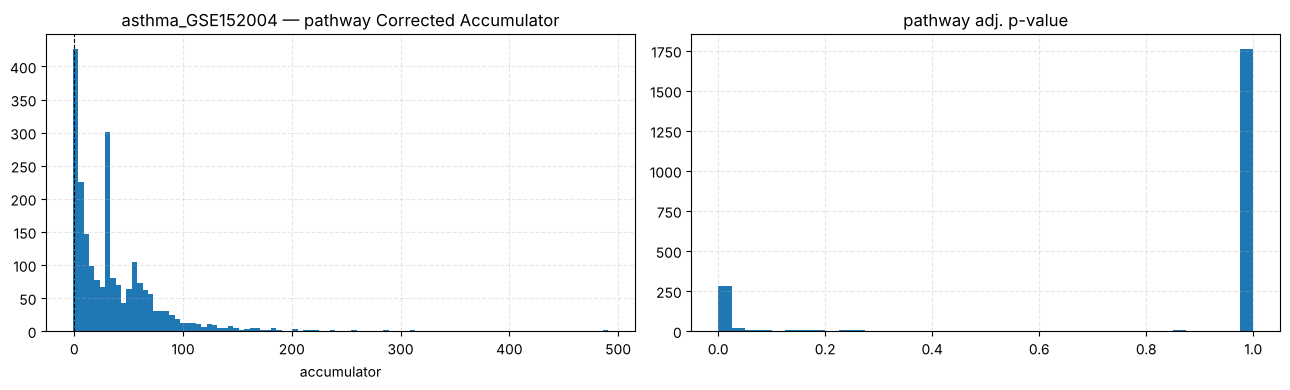

=== most POSITIVE (induced) pathways ===


,ID,Pathway Name,accumulator,adj_p,db
153,R-HSA-1430728,Metabolism,490.737507,1.0,Reactome
231,R-HSA-162582,Signaling Pathways,309.445990,1.0,Reactome
791,R-HSA-392499,Metabolism of proteins,285.017753,1.0,Reactome
748,R-HSA-382551,Transport of small molecules,256.464921,1.0,Reactome
2009,path:hsa01100,Metabolic pathways,254.710818,1.0,KEGG
1024,R-HSA-556833,Metabolism of lipids,239.715907,1.0,Reactome
212,R-HSA-15869,Nucleotide metabolism,220.574159,1.0,Reactome
295,R-HSA-168256,Immune System,218.152453,1.0,Reactome
1171,R-HSA-597592,Post-translational protein modification,215.172589,1.0,Reactome
1312,R-HSA-71291,Amino acid and derivative metabolism,211.981593,1.0,Reactome


=== most NEGATIVE (suppressed) pathways ===


,ID,Pathway Name,accumulator,adj_p,db
330,R-HSA-174577,Activation of C3 and C5,-1.217926,0.067435,Reactome
1819,R-HSA-9754189,Primitive streak formation,-0.948901,0.234557,Reactome
2086,path:hsa04612,Antigen processing and presentation,-0.874874,0.270509,KEGG
1545,R-HSA-8952158,RUNX3 regulates BCL2L11 (BIM) transcription,-0.633105,0.361646,Reactome
1072,R-HSA-5635851,GLI proteins bind promoters of Hh responsive g...,-0.579762,0.211375,Reactome
1749,R-HSA-9617828,FOXO-mediated transcription of cell cycle genes,-0.578518,0.860961,Reactome
1526,R-HSA-8941855,RUNX3 regulates CDKN1A transcription,-0.517372,0.933452,Reactome
1859,R-HSA-9796292,Formation of axial mesoderm,-0.491622,0.689967,Reactome
1874,R-HSA-9823730,Formation of definitive endoderm,-0.485695,1.000000,Reactome
1217,R-HSA-6804116,TP53 Regulates Transcription of Genes Involved...,-0.450992,1.000000,Reactome


In [7]:
pw = pd.read_csv(PW_SIG_PATH, sep='\t')
pw.columns = [c.strip() for c in pw.columns]
pw = pw.rename(columns={'Corrected Accumulator': 'accumulator', 'Adjusted pValue': 'adj_p'})
pw['ID'] = pw['ID'].astype(str).str.strip()
pw['db'] = np.where(pw['ID'].str.startswith('path:'), 'KEGG', 'Reactome')   # ID is the unique key

print('pathways:', len(pw), '| unique IDs:', pw.ID.nunique(),
      '| duplicated Pathway Names:', int(pw['Pathway Name'].duplicated().sum()))
print('by DB:', pw['db'].value_counts().to_dict())
print(f"accumulator: min={pw.accumulator.min():.1f}  max={pw.accumulator.max():.1f}  "
      f"median={pw.accumulator.median():.1f}  frac_negative={(pw.accumulator<0).mean():.3f}")
print(f"significant (adj_p<=0.05): {(pw.adj_p<=0.05).mean():.3f}  ({int((pw.adj_p<=0.05).sum())}/{len(pw)})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(pw.accumulator, bins=100); ax[0].axvline(0, color='k', lw=.8, ls='--')
ax[0].set_title(f'{DISEASE} — pathway Corrected Accumulator'); ax[0].set_xlabel('accumulator'); ax[0].grid(ls='--', alpha=.3)
ax[1].hist(pw.adj_p, bins=40); ax[1].set_title('pathway adj. p-value'); ax[1].grid(ls='--', alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_pathway_signature.png'), dpi=120); plt.show()

cols = ['ID', 'Pathway Name', 'accumulator', 'adj_p', 'db']
print('=== most POSITIVE (induced) pathways ==='); display(pw.sort_values('accumulator', ascending=False).head(15)[cols])
print('=== most NEGATIVE (suppressed) pathways ==='); display(pw.sort_values('accumulator').head(15)[cols])

### 0.6 Notes

- **Node sets.** DEG = 15,347 genes. MITHrIL = 15,825 network nodes (the same node set as the
  IPF and ALS runs): 11,457 genes, 2,886 metabolites, 208 glycans, 24 KEGG drugs, 1,250 miRNAs. 8,296 genes are in both; 7,051 DEG genes
  are not network nodes, and 3,161 MITHrIL gene nodes were not measured.
- **Per-gene values.** On the 8,296 shared genes, DEG log2FC and MITHrIL perturbation have
  Pearson r = 0.89, Spearman ρ = 0.91, sign agreement 0.92 (IPF: 0.71 / 0.84 / 0.87).
- **Significance.** 30.5% of the shared genes have DEG adj.p ≤ 0.05; 0.7% have MITHrIL
  adj.p ≤ 0.05, and 0.5% both.
- **Known-answer genes.** SERPINB2 and CCL26 keep a positive perturbation after propagation and
  rank 16th and 11th of the gene nodes by perturbation. CLCA1, absent from the DEG input, receives
  a small positive perturbation from its neighbours. POSTN and CST1, the two genes with the
  largest DEG fold-changes among them, are not network nodes, so they enter only the DEG runs.
- **Pathway signature.** 2,159 pathways (1,926 Reactome, 233 KEGG); 95.8% have a positive
  Corrected Accumulator (IPF ~78%), median 28.7, range −1.2 to 490.7; 299 (13.8%) have
  adj_p ≤ 0.05. The largest accumulators belong to the broadest pathways (Metabolism, Signaling
  Pathways, Metabolism of proteins, Immune System), all with adj_p = 1; the negative values are
  close to zero.

## 1. Connectivity-score runs

The five `bin_chen` runs of `logs/cs_runs.tsv` with `disease_run_id = asthma_GSE152004`
(all cell lines, drugs collapsed before CS). They differ only in the propagation / gene-universe
knobs:

| label | cs_mith | cs_on_LM | pathways |
|---|---|---|---|
| `DEG`     | 0 | 0 | no |
| `DEG_LM`  | 0 | 1 | no |
| `mith`    | 1 | 0 | no |
| `mith_LM` | 1 | 1 | no |
| `mith_pw` | 1 | 0 | yes |

Output schema: one row per *(drug, timepoint)* keyed by `pert_id` (e.g. `budesonide_24h`).
**Sign convention:** most-negative `connectivity_score` = strongest reversal of the asthma
signature.

In [4]:
CS_OUT = os.path.join(NETCOS_ROOT, 'connectivity_score', 'output', DISEASE)
log = pd.read_csv(os.path.join(NETCOS_ROOT, 'logs', 'cs_runs.tsv'), sep='\t')
log = log[(log.disease_run_id == DISEASE) & (log.CS_METHOD == 'bin_chen')].copy()

def run_label(r):
    if int(r.mith) == 0:
        return 'DEG_LM' if int(r.cs_on_LM) else 'DEG'
    if str(r.CS_ON_PATHWAYS).strip().lower() in ('1', '1.0', 'true'):
        return 'mith_pw'
    return 'mith_LM' if int(r.cs_on_LM) else 'mith'
log['label'] = log.apply(run_label, axis=1)
assert not log.label.duplicated().any(), 'more than one logged run per configuration'
RUN_FILES = dict(zip(log.label, log.cs_run_id + '.tsv'))
log.set_index('label')[['cs_run_id', 'n_drugs_total', 'n_disease_genes_after_common', 'elapsed_sec_total']]

,cs_run_id,n_drugs_total,n_disease_genes_after_common,elapsed_sec_total
label,,,,
DEG,27_10_2026_18_08_DEG_bin_chen_connectivity_score,9666,8546,160.591499
DEG_LM,27_10_2026_18_11_DEG_LM_bin_chen_connectivity_...,9666,886,37.868355
mith_pw,27_10_2026_18_11_mith_pw_bin_chen_connectivity...,9669,2159,63.579957
mith,27_10_2026_18_12_mith_bin_chen_connectivity_score,9669,15825,261.977580
mith_LM,27_10_2026_18_17_mith_LM_bin_chen_connectivity...,9669,763,40.303989


In [5]:
TIMEPOINTS = ['6h', '24h', '6h_24h']
ORDER = ['DEG', 'DEG_LM', 'mith', 'mith_LM', 'mith_pw']

def split_pert_id(pid):
    for tp in ('6h_24h', '24h', '6h'):
        if pid.endswith('_' + tp):
            return pid[:-(len(tp) + 1)], tp
    return pid, np.nan

def load_cs(label):
    df = pd.read_csv(os.path.join(CS_OUT, RUN_FILES[label]), sep='\t')
    drug_tp = df['pert_id'].apply(split_pert_id)
    df['drug'] = drug_tp.str[0]
    df['perturbation_time'] = drug_tp.str[1]
    df['drug_key'] = df['drug'].str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
    df['config'] = label
    return df

runs = {label: load_cs(label) for label in ORDER}
for label, df in runs.items():
    print(f'{label:8s}  rows={len(df):5d}  drugs={df.drug.nunique():5d}  '
          f'timepoints={df.perturbation_time.value_counts().to_dict()}  '
          f'CS[min={df.connectivity_score.min():+.3f}, max={df.connectivity_score.max():+.3f}]')

DEG       rows= 9666  drugs= 3222  timepoints={'24h': 3222, '6h_24h': 3222, '6h': 3222}  CS[min=-0.178, max=+0.180]
DEG_LM    rows= 9666  drugs= 3222  timepoints={'24h': 3222, '6h_24h': 3222, '6h': 3222}  CS[min=-0.192, max=+0.197]
mith      rows= 9669  drugs= 3223  timepoints={'24h': 3223, '6h': 3223, '6h_24h': 3223}  CS[min=-0.132, max=+0.138]
mith_LM   rows= 9669  drugs= 3223  timepoints={'24h': 3223, '6h': 3223, '6h_24h': 3223}  CS[min=-0.171, max=+0.210]
mith_pw   rows= 9669  drugs= 3223  timepoints={'24h': 3223, '6h': 3223, '6h_24h': 3223}  CS[min=-0.646, max=+0.592]


## 2. CS distributions across runs

In [10]:
def sign_table(runs):
    rows = []
    for label, df in runs.items():
        cs = df.connectivity_score
        sig = df.cs_p_value <= 0.05
        rows.append({'config': label, 'n': len(df),
                     'frac_negative': (cs < 0).mean(), 'frac_sig(p<=.05)': sig.mean(),
                     'frac_sig_negative': (sig & (cs < 0)).mean(),
                     'cs_min': cs.min(), 'cs_max': cs.max(),
                     'cs_p01': cs.quantile(0.01), 'cs_p99': cs.quantile(0.99)})
    return pd.DataFrame(rows).set_index('config').round(4)
sign_table(runs)

,n,frac_negative,frac_sig(p<=.05),frac_sig_negative,cs_min,cs_max,cs_p01,cs_p99
config,,,,,,,,
DEG,9666,0.5744,0.7057,0.3933,-0.1784,0.1798,-0.1257,0.1225
DEG_LM,9666,0.4806,0.1835,0.0803,-0.1921,0.1971,-0.1268,0.1372
mith,9669,0.3174,0.9983,0.3174,-0.1316,0.1382,-0.0838,0.1088
mith_LM,9669,0.2890,0.2228,0.0256,-0.1706,0.2098,-0.1107,0.1575
mith_pw,9669,0.6153,0.9798,0.6023,-0.6457,0.5916,-0.4976,0.4764


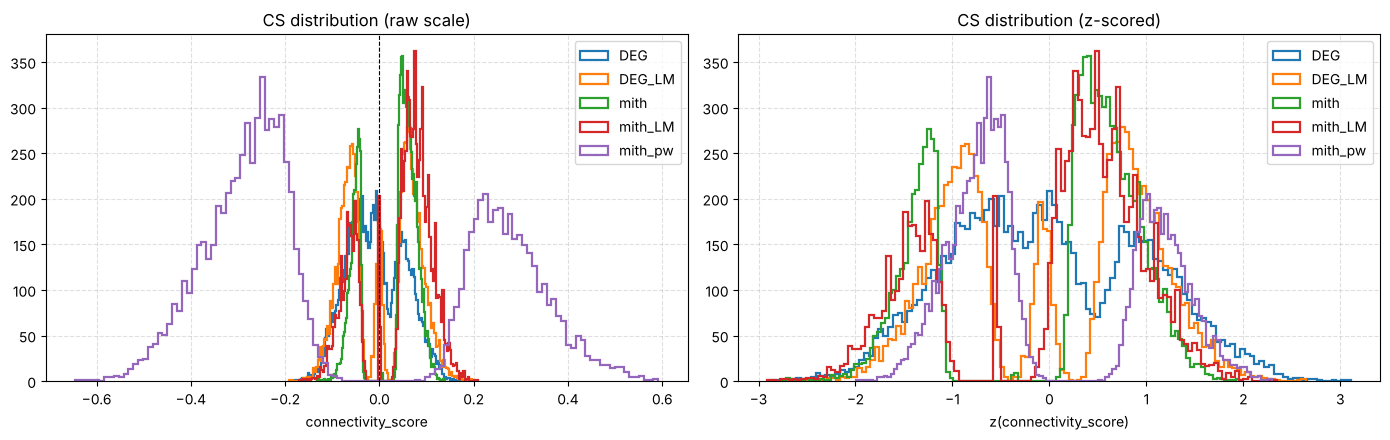

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for label, df in runs.items():
    axes[0].hist(df.connectivity_score, bins=120, histtype='step', lw=1.6, label=label)
    z = (df.connectivity_score - df.connectivity_score.mean()) / df.connectivity_score.std()
    axes[1].hist(z, bins=120, histtype='step', lw=1.6, label=label)
axes[0].axvline(0, color='k', lw=0.8, ls='--'); axes[0].set_title('CS distribution (raw scale)')
axes[0].set_xlabel('connectivity_score'); axes[1].set_title('CS distribution (z-scored)')
axes[1].set_xlabel('z(connectivity_score)')
for a in axes: a.legend(); a.grid(ls='--', alpha=.4)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_cs_distributions.png'), dpi=120); plt.show()

## 3. Sanity check: does negative CS mean reversal?

If the most-negative CS are reversers, CS should be positively correlated with the gene-level
`pearson` / `spearman` between drug and disease signature.

In [12]:
for label, df in runs.items():
    r = stats.spearmanr(df.connectivity_score, df.spearman).statistic
    rp = stats.spearmanr(df.connectivity_score, df.pearson).statistic
    print(f'{label:8s}  spearman(CS, gene-spearman)={r:+.3f}   spearman(CS, gene-pearson)={rp:+.3f}')

DEG       spearman(CS, gene-spearman)=+0.974   spearman(CS, gene-pearson)=+0.863
DEG_LM    spearman(CS, gene-spearman)=+0.906   spearman(CS, gene-pearson)=+0.701
mith      spearman(CS, gene-spearman)=+0.942   spearman(CS, gene-pearson)=+0.703
mith_LM   spearman(CS, gene-spearman)=+0.884   spearman(CS, gene-pearson)=+0.535
mith_pw   spearman(CS, gene-spearman)=+0.923   spearman(CS, gene-pearson)=+0.843


## 4. Top-ranking drugs per run

Most-negative CS among significant rows (`cs_p_value <= 0.05`), pooled `6h_24h` timepoint.

In [13]:
def top_ranking_drugs(data, pval=0.05, perturbation_time=None, n_best=20, ascending=True):
    d = data if perturbation_time is None else data[data.perturbation_time == perturbation_time]
    d = d[d.cs_p_value <= pval]
    cols = ['drug', 'perturbation_time', 'connectivity_score', 'cs_p_value', 'pearson', 'spearman', 'cos_sim']
    return d[cols].sort_values('connectivity_score', ascending=ascending).head(n_best)

for label in ORDER:
    n_sig = int(((runs[label].perturbation_time == '6h_24h') & (runs[label].cs_p_value <= 0.05)).sum())
    print(f'=== {label} — 6h_24h — {n_sig} signatures with cs_p_value <= 0.05 ===')
    display(top_ranking_drugs(runs[label], perturbation_time='6h_24h', n_best=15))

=== DEG — 6h_24h — 2250 signatures with cs_p_value <= 0.05 ===


,drug,perturbation_time,connectivity_score,cs_p_value,pearson,spearman,cos_sim
7309,homoharringtonine,6h_24h,-0.173708,0.0,-0.088425,-0.184071,-0.087235
6109,calyculin,6h_24h,-0.167974,0.0,-0.096046,-0.187697,-0.091158
8917,safrolglycol,6h_24h,-0.164302,0.0,-0.092763,-0.174699,-0.085394
5392,VX-702,6h_24h,-0.160748,0.0,-0.126490,-0.199845,-0.119783
4696,QL-X-138,6h_24h,-0.158837,0.0,-0.098500,-0.162910,-0.096569
9571,vincamine,6h_24h,-0.154207,0.0,-0.075385,-0.154146,-0.065675
2449,BRD-K71427192,6h_24h,-0.153469,0.0,-0.073117,-0.158119,-0.062481
6784,emetine,6h_24h,-0.151235,0.0,-0.080323,-0.161032,-0.080715
6190,cephaeline,6h_24h,-0.151133,0.0,-0.079279,-0.163092,-0.079821
7342,hydrocotarnine,6h_24h,-0.150583,0.0,-0.084200,-0.164904,-0.074163


=== DEG_LM — 6h_24h — 578 signatures with cs_p_value <= 0.05 ===


,drug,perturbation_time,connectivity_score,cs_p_value,pearson,spearman,cos_sim
8677,purvalanol-b,6h_24h,-0.163054,0.000,-0.093945,-0.111470,-0.099555
8917,safrolglycol,6h_24h,-0.159859,0.000,-0.076898,-0.140017,-0.089474
8836,rilmenidine,6h_24h,-0.155458,0.000,-0.114236,-0.120988,-0.125078
6301,cisapride,6h_24h,-0.148500,0.000,-0.036010,-0.101389,-0.045733
1732,BRD-K41797142,6h_24h,-0.146227,0.000,-0.043248,-0.089781,-0.048471
4147,LY-344864,6h_24h,-0.145305,0.000,-0.086663,-0.124764,-0.088320
6190,cephaeline,6h_24h,-0.143089,0.003,-0.036180,-0.095713,-0.040587
9475,tyrphostin-AG-527,6h_24h,-0.142069,0.000,-0.078559,-0.115435,-0.080157
7309,homoharringtonine,6h_24h,-0.138307,0.001,-0.016453,-0.107002,-0.023151
4990,SCH-28080,6h_24h,-0.138286,0.001,-0.074915,-0.119325,-0.069905


=== mith — 6h_24h — 3217 signatures with cs_p_value <= 0.05 ===


,drug,perturbation_time,connectivity_score,cs_p_value,pearson,spearman,cos_sim
7313,homoharringtonine,6h_24h,-0.128824,0.0,-0.034918,-0.125225,-0.032796
6194,cephaeline,6h_24h,-0.128702,0.0,-0.031858,-0.128196,-0.030833
6788,emetine,6h_24h,-0.118098,0.0,-0.028753,-0.117656,-0.027738
5132,ST-022313,6h_24h,-0.105878,0.0,-0.028611,-0.068231,-0.024264
9557,verrucarin-a,6h_24h,-0.103283,0.0,-0.039222,-0.105235,-0.037518
5777,anisomycin,6h_24h,-0.100935,0.0,0.001001,-0.074648,0.002128
9458,tyrphostin-AG-126,6h_24h,-0.100454,0.0,-0.026490,-0.091809,-0.023287
6635,dihydroobliquin,6h_24h,-0.096796,0.0,-0.050546,-0.073830,-0.048250
5321,TUL-XXI039,6h_24h,-0.096485,0.0,-0.030777,-0.081731,-0.033611
4994,SCH-28080,6h_24h,-0.093808,0.0,-0.045854,-0.079001,-0.044918


=== mith_LM — 6h_24h — 752 signatures with cs_p_value <= 0.05 ===


,drug,perturbation_time,connectivity_score,cs_p_value,pearson,spearman,cos_sim
8840,rilmenidine,6h_24h,-0.160007,0.000,-0.132746,-0.099513,-0.133224
1730,BRD-K41670583,6h_24h,-0.149866,0.000,-0.109983,-0.155276,-0.104296
6194,cephaeline,6h_24h,-0.147227,0.001,-0.043985,-0.097415,-0.044709
2762,BRD-K83589469,6h_24h,-0.144396,0.001,-0.073047,-0.092127,-0.074129
1526,BRD-K32132269,6h_24h,-0.139078,0.000,-0.067728,-0.103526,-0.067928
7643,lidocaine,6h_24h,-0.131301,0.003,-0.021616,-0.084334,-0.020978
6776,eliprodil,6h_24h,-0.126257,0.005,-0.060167,-0.094403,-0.058352
1736,BRD-K41797142,6h_24h,-0.126209,0.007,0.013058,-0.065621,0.011982
4151,LY-344864,6h_24h,-0.125859,0.005,-0.071479,-0.102141,-0.072212
8681,purvalanol-b,6h_24h,-0.125825,0.006,-0.045871,-0.060504,-0.046608


=== mith_pw — 6h_24h — 3166 signatures with cs_p_value <= 0.05 ===


,drug,perturbation_time,connectivity_score,cs_p_value,pearson,spearman,cos_sim
6911,estrone,6h_24h,-0.645708,0.0,-0.712372,-0.770050,-0.821555
4946,SB-258585,6h_24h,-0.583391,0.0,-0.717563,-0.731013,-0.819899
6620,dihydrexidine,6h_24h,-0.565970,0.0,-0.715758,-0.664756,-0.814489
2105,BRD-K58279162,6h_24h,-0.558715,0.0,-0.657459,-0.631382,-0.779595
5825,arvanil,6h_24h,-0.554859,0.0,-0.490154,-0.544443,-0.687405
5180,ST-4062971,6h_24h,-0.547625,0.0,-0.608008,-0.587031,-0.725485
6683,dipropyl-dopamine,6h_24h,-0.545192,0.0,-0.676972,-0.650125,-0.744279
2393,BRD-K69569876,6h_24h,-0.537996,0.0,-0.702264,-0.713097,-0.819014
6797,endecaphyllin-x,6h_24h,-0.534575,0.0,-0.533513,-0.652205,-0.707437
2876,BRD-K89009594,6h_24h,-0.531702,0.0,-0.621121,-0.648931,-0.757998


## 5. Do the runs agree on which drugs win?

Drug × configuration on the pooled `6h_24h` CS (joined on the normalised `drug_key`; duplicated
keys within a run are averaged).

drugs in common across all runs (6h_24h): 3221


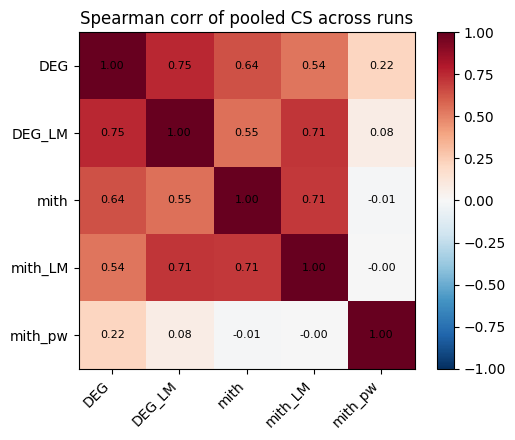

,DEG,DEG_LM,mith,mith_LM,mith_pw
DEG,1.000,0.752,0.636,0.536,0.216
DEG_LM,0.752,1.000,0.550,0.711,0.077
mith,0.636,0.550,1.000,0.709,-0.013
mith_LM,0.536,0.711,0.709,1.000,-0.004
mith_pw,0.216,0.077,-0.013,-0.004,1.000


In [8]:
pooled, name_map = {}, {}
for label, df in runs.items():
    sub = df[df.perturbation_time == '6h_24h']
    pooled[label] = sub.groupby('drug_key')['connectivity_score'].mean()
    name_map.update(dict(zip(sub['drug_key'], sub['drug'])))
Pm = pd.DataFrame(pooled)[ORDER]
print('drugs in common across all runs (6h_24h):', Pm.dropna().shape[0])
corr_spear = Pm.corr(method='spearman')
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr_spear.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER, rotation=45, ha='right')
ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(ORDER)
for i in range(len(ORDER)):
    for j in range(len(ORDER)):
        ax.text(j, i, f'{corr_spear.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('Spearman corr of pooled CS across runs'); plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_cross_run_corr.png'), dpi=120); plt.show()
corr_spear.round(3)

In [15]:
# Consensus: rank each drug within each run (1 = strongest reverser), average ranks over the MITHrIL runs.
R = Pm.rank(method='average').dropna()
R['mean_rank'] = R[ORDER].mean(axis=1)
R['mean_rank_mith'] = R[['mith', 'mith_LM', 'mith_pw']].mean(axis=1)
R.index = R.index.map(lambda k: name_map.get(k, k))
R.sort_values('mean_rank_mith').head(25).round(1)

,DEG,DEG_LM,mith,mith_LM,mith_pw,mean_rank,mean_rank_mith
drug_key,,,,,,,
cephaeline,9.0,7.0,2.0,3.0,45.0,13.2,16.7
emetine,8.0,26.0,3.0,44.0,90.0,34.2,45.7
homoharringtonine,1.0,9.0,1.0,13.0,131.5,31.1,48.5
verrucarin-a,15.0,43.0,5.0,102.5,67.0,46.5,58.2
marmesin,419.0,340.0,54.0,58.0,74.0,189.0,62.0
narciclasine,12.0,22.0,18.0,95.0,80.0,45.4,64.3
tyrphostin-AG-126,18.0,52.0,7.0,177.0,37.0,58.2,73.7
indoprofen,403.0,639.0,92.0,93.0,60.0,257.4,81.7
RS-79948,267.0,125.0,190.0,39.0,61.0,136.4,96.7


## 6. Where do the repoDB-labelled asthma drugs fall? (descriptive)

The asthma pairs of `repodb_signature_lincs_pairs.tsv` (C0004096, *Asthma*: 18 approved, 14
not-approved, plus the 5 `conflict` pairs, all glucocorticoids, shown separately because they are
excluded from the benchmark) matched to the runs through their L1000 `pert_iname` (one name differs between
`lincs_sig_info_new.csv` and the CS runs and is aliased). Values are the pooled `6h_24h`
`connectivity_score` of each drug (more negative = stronger reversal). The CS scale differs
between runs (`mith_pw` spans about ±0.6, the others about ±0.2), so each run has its own y-axis.
A first look only; the selection of the labelled drugs for the benchmark comes later.

In [9]:
pairs = pd.read_csv(os.path.join(NETCOS_ROOT, 'other_outputs', 'validations',
                                 'drug_disease_pairs_validation', 'repodb_signature_lincs_pairs.tsv'), sep='\t')
pairs = pairs[pairs.ind_id == 'C0004096'].copy()
pairs['iname'] = pairs['lincs_pert_inames'].astype(str).str.split('|')
pairs = pairs.explode('iname')
pairs['drug_key'] = pairs['iname'].str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
# L1000 name in the CS runs differs from the pert_iname of lincs_sig_info_new.csv
CS_NAME_ALIAS = {'beclometasone': 'beclomethasonedipropionate'}
pairs['drug_key'] = pairs['drug_key'].replace(CS_NAME_ALIAS)

lab = pairs.merge(Pm, left_on='drug_key', right_index=True, how='left')     # pooled 6h_24h CS
lab = lab.groupby(['label', 'drugbank_id', 'drug_name', 'failed_statuses', 'failed_trials'], dropna=False)[ORDER].mean().reset_index()
# not-approved subtype from the ClinicalTrials.gov overall status of the pair's trials:
# 'withdrawn only' = every trial of the pair stopped before enrolling its first participant
st = lab['failed_statuses'].fillna('')
lab['na_subtype'] = np.where(lab.label != 'not_approved', '',
                    np.where(st.str.split('|').apply(lambda x: set(x) == {'Withdrawn'}), 'withdrawn only', 'terminated/suspended'))
absent = lab[lab[ORDER].isna().all(axis=1)]
print('labelled pairs:', lab.label.value_counts().to_dict())
print('not in the CS drug universe:', absent.groupby('label').size().to_dict())
print('   ', '; '.join(f"{r.drug_name if isinstance(r.drug_name, str) else r.drugbank_id} ({r.label})" for r in absent.itertuples()))
display(lab.groupby('label')[ORDER].median().round(4))
lab.sort_values(['label', 'mith']).round(4)[['label', 'na_subtype', 'drugbank_id', 'drug_name', 'failed_statuses', 'failed_trials'] + ORDER]

labelled pairs: {'approved': 18, 'not_approved': 14, 'conflict': 5}
not in the CS drug universe: {'approved': 9, 'not_approved': 5}
    theophylline (approved); zafirlukast (approved); diprophylline (approved); orciprenaline (approved); terbutaline (approved); methylprednisolone (approved); cromoglicic acid (approved); pranlukast (approved); acefylline (approved); azithromycin (not_approved); bosentan (not_approved); epinephrine (not_approved); salbutamol (not_approved); DB01394 (not_approved)


,DEG,DEG_LM,mith,mith_LM,mith_pw
label,,,,,
approved,0.0281,0.0737,0.0499,0.0736,0.2122
conflict,0.0591,0.0629,0.0660,0.0841,0.2339
not_approved,-0.0084,-0.0009,0.0708,0.0475,-0.2175


,label,na_subtype,drugbank_id,drug_name,failed_statuses,failed_trials,DEG,DEG_LM,mith,mith_LM,mith_pw
16,approved,,DB12017,ozagrel,NaN,NaN,-0.0254,-0.0595,-0.0690,-0.0763,0.3103
2,approved,,DB00368,norepinephrine,NaN,NaN,-0.0027,0.0790,-0.0685,0.0576,0.3983
8,approved,,DB00741,hydrocortisone,NaN,NaN,0.0281,0.0670,-0.0428,0.0665,0.1870
4,approved,,DB00443,betamethasone,NaN,NaN,0.0471,0.0760,0.0472,0.0890,0.3301
14,approved,,DB05266,ibudilast,NaN,NaN,0.0519,0.1065,0.0499,0.0944,-0.2368
0,approved,,DB00180,flunisolide,NaN,NaN,0.0012,0.0737,0.0503,0.0795,-0.2678
6,approved,,DB00620,triamcinolone,NaN,NaN,0.0465,-0.0158,0.0578,0.0736,0.2122
3,approved,,DB00394,beclometasone dipropionate,NaN,NaN,0.0872,0.1030,0.0787,0.0944,0.2640
15,approved,,DB07615,tranilast,NaN,NaN,0.0113,0.0022,0.0859,0.0658,-0.2436
1,approved,,DB00277,theophylline,NaN,NaN,NaN,NaN,NaN,NaN,NaN


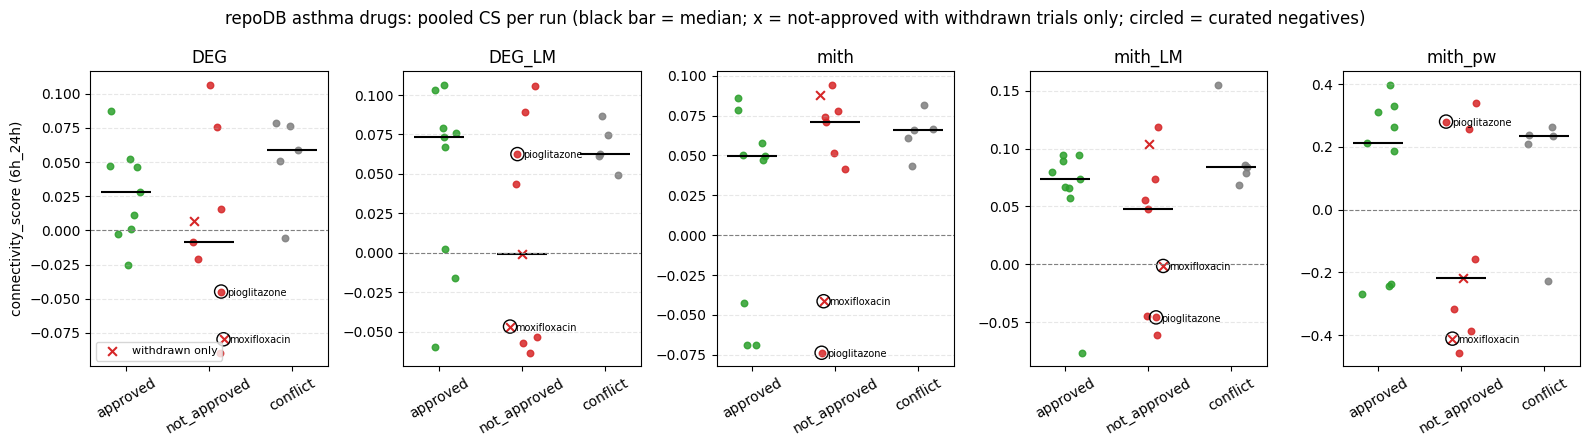

In [10]:
# not-approved pairs kept as negatives after the manual curation of the trial stop reason (see the cell below)
CURATED_NEGATIVES = ['pioglitazone', 'moxifloxacin']
LABELS = [('approved', '#2ca02c'), ('not_approved', '#d62728'), ('conflict', '#7f7f7f')]
fig, axes = plt.subplots(1, len(ORDER), figsize=(16, 4.5))
rng = np.random.default_rng(0)
for ax, label in zip(axes, ORDER):
    for j, (lb, col) in enumerate(LABELS):
        sub = lab[lab.label == lb].dropna(subset=[label])
        jit = j + rng.uniform(-.2, .2, len(sub))
        wd = (sub.na_subtype == 'withdrawn only').values
        ax.scatter(jit[~wd], sub.loc[~wd, label], s=22, color=col, alpha=.85)
        ax.scatter(jit[wd], sub.loc[wd, label], s=40, color=col, marker='x', label='withdrawn only' if (wd.any() and label == ORDER[0]) else None)
        for xx, (_, r) in zip(jit, sub.iterrows()):          # curated not-approved negatives (stop reason, 30/10)
            if lb == 'not_approved' and r.drug_name in CURATED_NEGATIVES:
                ax.annotate(r.drug_name, (xx, r[label]), xytext=(4, -3), textcoords='offset points', fontsize=7)
                ax.scatter(xx, r[label], s=90, facecolors='none', edgecolors='k', lw=1)
        v = sub[label]
        ax.hlines(v.median(), j - .3, j + .3, color='k', lw=1.5)
    ax.axhline(0, color='grey', ls='--', lw=.8)
    ax.set_xticks(range(len(LABELS))); ax.set_xticklabels([l for l, _ in LABELS], rotation=30)
    ax.set_title(label); ax.grid(axis='y', ls='--', alpha=.3)
axes[0].set_ylabel('connectivity_score (6h_24h)')
axes[0].legend(fontsize=8, loc='lower left')
fig.suptitle('repoDB asthma drugs: pooled CS per run (black bar = median; x = not-approved with withdrawn trials only; circled = curated negatives)')
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_repodb_drugs_in_rankings.png'), dpi=120); plt.show()

### 6.0 Manual curation of the not-approved pairs (stop reason)

repoDB labels a pair not-approved when a trial of the drug for the disease is Terminated, Suspended or Withdrawn on ClinicalTrials.gov. The trial's "Why Study Stopped" text (repoDB `DetailedStatus`) was classified by stop reason (`src/validations/drug_disease_pairs_validation/06_repodb_stop_reason.py`; curated table `other_outputs/validations/drug_disease_pairs_validation/repodb_why_stopped_classification.tsv`) and the 14 asthma not-approved pairs were reviewed by hand:

| drug | trial | stop reason | curated label |
|---|---|---|---|
| pioglitazone | NCT00787644, Terminated, phase 2 | "new safety concerns which emerged about pioglitazone during the trial" | negative (safety) |
| moxifloxacin | NCT01721135, Withdrawn, phase 1 | "toxicology findings after screening started but before first subject first dose" | weak negative (preclinical safety, no participant dosed) |
| azithromycin, lansoprazole, bosentan, dobutamine, epinephrine, salmeterol, formoterol, salbutamol, atorvastatin, DB00332, DB01394 | | investigator left, recruitment, protocol or analytical method, data no longer needed, development stopped, COVID-19, funding, IND withdrawn, a grant summary record | uninformative |
| fenoterol | NCT02177370, Terminated | no text | unknown |

No asthma pair was stopped for lack of efficacy. Both curated negatives are safety stops about the drug in general, not observations in asthma patients. The two drugs are circled and named in the plot above; in `mith` they are the two not-approved drugs with negative CS. With at most two negatives, an AUROC of approved vs curated not-approved is not computable in a meaningful way, and the AUROC of section 6.1 compares the approved drugs with a group that is mostly administrative stops.

### 6.1 AUROC of the CS on approved vs not-approved pairs

Positives = approved, negatives = not-approved (conflict pairs excluded), drugs with a CS row
only. The score is −CS, so AUROC > 0.5 means approved drugs tend to have more negative CS than
not-approved ones. AUROC equals the Mann–Whitney U statistic divided by n_pos·n_neg; the
two-sided p-value is the exact Mann–Whitney test. The table is computed with all not-approved
pairs and without the pairs whose trials are all *Withdrawn* (stopped before enrolling the first
participant, ClinicalTrials.gov Overall Recruitment Status), i.e. where the drug was never tested. The 95% interval is a percentile bootstrap
(2,000 resamples within each class). With 9 vs 9 drugs and five runs, the intervals are wide and
the p-values are not corrected for the five comparisons.

In [18]:
def auroc_table(lab, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for label in ORDER:
        d = lab[lab.label.isin(['approved', 'not_approved'])][['label', label]].dropna()
        pos = -d.loc[d.label == 'approved', label].values      # score = -CS
        neg = -d.loc[d.label == 'not_approved', label].values
        mw = stats.mannwhitneyu(pos, neg, alternative='two-sided', method='exact')
        auc = mw.statistic / (len(pos) * len(neg))
        boot = []
        for _ in range(n_boot):
            p = rng.choice(pos, len(pos)); n = rng.choice(neg, len(neg))
            boot.append(stats.mannwhitneyu(p, n).statistic / (len(p) * len(n)))
        lo, hi = np.percentile(boot, [2.5, 97.5])
        rows.append({'config': label, 'n_approved': len(pos), 'n_not_approved': len(neg),
                     'AUROC': auc, 'CI95_low': lo, 'CI95_high': hi, 'p_MannWhitney': mw.pvalue})
    return pd.DataFrame(rows).set_index('config').round(3)

auc_tab = auroc_table(lab)
auc_tab_nowd = auroc_table(lab[lab.na_subtype != 'withdrawn only'])
display(pd.concat({'all not-approved': auc_tab, 'without withdrawn-only': auc_tab_nowd}, axis=1)
        .loc[:, (slice(None), ['n_not_approved', 'AUROC', 'CI95_low', 'CI95_high', 'p_MannWhitney'])])

all not-approved                                         without withdrawn-only                                        
          n_not_approved  AUROC CI95_low CI95_high p_MannWhitney         n_not_approved  AUROC CI95_low CI95_high p_MannWhitney
config                                                                                                                         
DEG                    9  0.321    0.086     0.593         0.222                      7  0.365    0.063     0.683         0.408
DEG_LM                 9  0.321    0.074     0.593         0.222                      7  0.365    0.095     0.667         0.408
mith                   9  0.630    0.358     0.877         0.387                      7  0.619    0.317     0.905         0.470
mith_LM                9  0.358    0.099     0.654         0.340                      7  0.302    0.032     0.619         0.210
mith_pw                9  0.309    0.086     0.580         0.190                      7  0.349    0.095     0.667         0.351

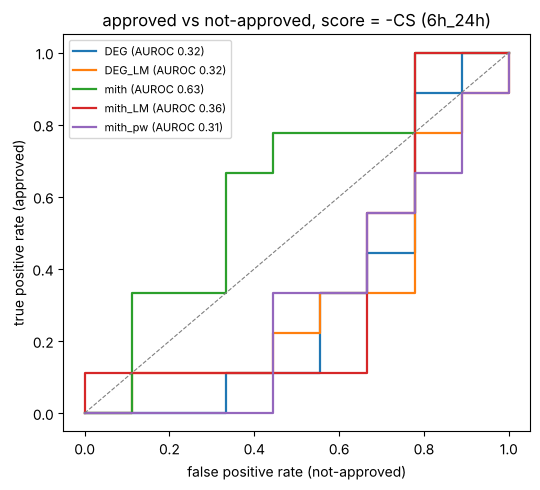

In [19]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(5.5, 5))
for label in ORDER:
    d = lab[lab.label.isin(['approved', 'not_approved'])][['label', label]].dropna()
    fpr, tpr, _ = roc_curve((d.label == 'approved').astype(int), -d[label])
    ax.plot(fpr, tpr, lw=1.6, label=f"{label} (AUROC {auc_tab.loc[label, 'AUROC']:.2f})")
ax.plot([0, 1], [0, 1], color='grey', ls='--', lw=.8)
ax.set_xlabel('false positive rate (not-approved)'); ax.set_ylabel('true positive rate (approved)')
ax.set_title('approved vs not-approved, score = -CS (6h_24h)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_repodb_auroc.png'), dpi=120); plt.show()

In [20]:
# Glucocorticoids among the labelled drugs (approved + conflict) and four glucocorticoid-induced genes in the DEG signature
GC = ['hydrocortisone', 'betamethasone', 'flunisolide', 'triamcinolone', 'beclometasone dipropionate',
      'prednisone', 'prednisolone', 'dexamethasone', 'budesonide', 'mometasone furoate']
gc = lab[lab.drug_name.isin(GC)].set_index('drug_name')[ORDER]
print('glucocorticoids with a CS row:', len(gc))
display(gc.describe().loc[['min', '50%', 'max']].round(3))
GC_INDUCED = {'FKBP5': '2289', 'TSC22D3': '1831', 'ZBTB16': '7704', 'PER1': '5187'}
deg.set_index('gene_id').reindex(list(GC_INDUCED.values()))[['DE_log2_FC', 'adj.p.value']].set_axis(list(GC_INDUCED), axis=0).round(4)

glucocorticoids with a CS row: 10


,DEG,DEG_LM,mith,mith_LM,mith_pw
min,-0.006,-0.016,-0.043,0.067,-0.268
50%,0.049,0.070,0.059,0.082,0.223
max,0.087,0.103,0.082,0.155,0.330


,DE_log2_FC,adj.p.value
FKBP5,-0.0792,0.2665
TSC22D3,-0.0725,0.0883
ZBTB16,-0.1041,0.4150
PER1,-0.0631,0.3052


## 7. Notes

- **Drug universe.** 3,222 drugs in the DEG runs and 3,223 in the MITHrIL runs, each at 6 h,
  24 h and pooled 6h_24h.
- **Sign convention.** CS correlates positively with the gene-level Spearman correlation between
  drug and disease signatures in every run (+0.88 to +0.97), as expected if the most-negative CS
  are the strongest reversers.
- **Distributions and significance.** `mith_pw` has the widest range (−0.65 to +0.59) and is the
  only run with more negative than positive scores among the MITHrIL runs (61.5% negative). In
  `DEG` (70.6%), `mith` (99.8%) and `mith_pw` (98.0%) most signatures have `cs_p_value <= 0.05`,
  so the p-value hardly separates drugs there; in the landmark runs the share is 18–22%.
- **Top of the rankings.** In `DEG` and `mith` the strongest reversers include the
  protein-synthesis inhibitors also found at the top of the IPF rankings (homoharringtonine,
  emetine, cephaeline, verrucarin A, narciclasine, anisomycin, cycloheximide). The `mith_pw` top
  is different (estrone, SB-258585, dihydrexidine, dipropyl-dopamine, eticlopride, CGP-12177).
- **Agreement between runs.** The four gene-level runs correlate with each other (Spearman
  0.54–0.75 on pooled CS); `mith_pw` does not correlate with any of them (−0.01 to 0.22).
- **repoDB-labelled drugs.** 14 of the 32 labelled asthma drugs have no CS row: 9 approved
  (including theophylline, terbutaline, orciprenaline, zafirlukast, methylprednisolone) and 5
  not-approved (including salbutamol and epinephrine). They are absent from the CS drug universe,
  not from L1000. Among the drugs present (9 approved, 9 not-approved), the median pooled CS of
  the approved drugs is positive in every run (0.028 to 0.212).
- **AUROC (section 6.1).** Approved vs not-approved with score −CS: 0.32 (DEG), 0.32 (DEG_LM),
  0.63 (mith), 0.36 (mith_LM), 0.31 (mith_pw); all 95% bootstrap intervals include 0.5 and no
  Mann–Whitney p is below 0.19. With 9 vs 9 drugs these values do not separate the two classes in
  either direction.
- **Withdrawn-only not-approved pairs.** Moxifloxacin (NCT01721135) and salmeterol (NCT02218762,
  NCT02496715) have only Withdrawn trials. Without them (9 approved vs 7 not-approved) the AUROC
  values are 0.37 (DEG), 0.37 (DEG_LM), 0.62 (mith), 0.30 (mith_LM), 0.35 (mith_pw). In `mith` the
  two not-approved drugs with negative CS are pioglitazone (one Withdrawn and one Terminated trial)
  and moxifloxacin (Withdrawn only).
- **`mith_pw` values.** In `mith_pw` the labelled drugs fall into two groups, around +0.2 to +0.4
  and around −0.2 to −0.3.
- **Glucocorticoids.** The ten glucocorticoids with a CS row (approved and conflict) have a
  positive median pooled CS in every run (0.049 to 0.223; table above), i.e. on average they do
  not reverse the signature. The four glucocorticoid-induced
  genes FKBP5, TSC22D3, ZBTB16 and PER1 are not higher in the asthma signature (log2FC −0.06 to
  −0.10, not significant).